In [1]:
from __future__ import annotations

from typing import List, Tuple
import numpy as np
import qutip as qt


# ============================================================
# Local operators
# ============================================================

def op_on_site(op: qt.Qobj, N: int, site: int) -> qt.Qobj:
    if not (0 <= site < N):
        raise ValueError("site out of range")
    ops = [qt.qeye(2)] * N
    ops[site] = op
    return qt.tensor(ops)


def two_site_op(opA: qt.Qobj, opB: qt.Qobj, N: int, i: int, j: int) -> qt.Qobj:
    if i == j:
        raise ValueError("i and j must differ")
    ops = [qt.qeye(2)] * N
    ops[i] = opA
    ops[j] = opB
    return qt.tensor(ops)


# ============================================================
# Hamiltonian
# ============================================================

def kac_factor(N: int, alpha: float) -> float:
    r = np.arange(1, N, dtype=float)
    return np.sum((N - r) / (r ** alpha)) / (N - 1)


def build_H_B_Jz_Jlong(
    N: int,
    Bx: float,
    Jz: float,
    Jx: float,
    alpha: float,
    kac: bool = True,
) -> qt.Qobj:

    if N < 2:
        raise ValueError("N must be >= 2")

    sx, sz = qt.sigmax(), qt.sigmaz()
    H = 0

    # Kac normalization
    if kac:
        Jz = Jz / kac_factor(N, alpha)

    # field x
    for j in range(N):
        H += Bx * op_on_site(sx, N, j)

    # xx nearest neighbor
    for j in range(N - 1):
        H += Jx * two_site_op(sx, sx, N, j, j + 1)

    # zz long-range
    if alpha >= 100:
        for j in range(N - 1):
            H += Jz * two_site_op(sz, sz, N, j, j + 1)
    else:
        for i in range(N):
            for j in range(i + 1, N):
                r = j - i
                H += (Jz / (r ** alpha)) * two_site_op(sz, sz, N, i, j)

    return H


# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H: qt.Qobj):
    evals, evecs = H.eigenstates()
    return np.array(evals), evecs


# ============================================================
# Product states
# ============================================================

def product_state_angles(thetas: np.ndarray, phis: np.ndarray) -> qt.Qobj:
    thetas = np.asarray(thetas)
    phis = np.asarray(phis)

    if thetas.shape != phis.shape:
        raise ValueError("shape mismatch")

    kets = [
        np.cos(t / 2) * qt.basis(2, 0)
        + np.exp(1j * p) * np.sin(t / 2) * qt.basis(2, 1)
        for t, p in zip(thetas, phis)
    ]

    return qt.tensor(kets).unit()


def product_state_x_pm(pm: str) -> qt.Qobj:
    pm = pm.strip()

    N = len(pm)
    thetas = np.full(N, np.pi / 2)
    phis = np.array([0 if c == "+" else np.pi for c in pm])

    return product_state_angles(thetas, phis)


def product_state_from_bitstring(bits: str) -> qt.Qobj:
    bits = bits.strip()

    kets = [qt.basis(2, int(b)) for b in bits]
    return qt.tensor(kets).unit()


# ============================================================
# Fidelity from spectrum
# ============================================================

def fidelity_from_spectrum(
    evals: np.ndarray,
    coeffs: np.ndarray,
    times: np.ndarray
) -> np.ndarray:

    weights = np.abs(coeffs) ** 2

    F = np.zeros(len(times))

    for k, t in enumerate(times):
        amp = np.sum(weights * np.exp(-1j * evals * t))
        F[k] = np.abs(amp) ** 2

    return F

In [ ]:
import numpy as np
import qutip as qt
import pandas as pd
import os

# =========================
# Parameters
# =========================

N = 6

Jz = 100
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1]

alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax = 100
times = np.linspace(0, tmax, 500)

# =========================
# Initial state
# =========================

psi0 = product_state_from_bitstring("010" + "1"*(N-3))  # 3 excitations on left imbalance
rho0 = psi0 * psi0.dag()

# =========================
# Precompute logical mask
# =========================

dim = 2**N

left_sites = list(range(N//2))
right_sites = list(range(N//2, N))

plus_mask = np.zeros(dim, dtype=bool)

for idx in range(dim):

    bits = format(idx, f"0{N}b")

    nL = sum(int(bits[i]) for i in left_sites)
    nR = sum(int(bits[i]) for i in right_sites)

    M = nR - nL

    if M > 0:
        plus_mask[idx] = True

# =========================
# Save directory
# =========================

save_dir = "ED_Data/OpenMemory/LogicalBitFlip"
os.makedirs(save_dir, exist_ok=True)

# =========================
# Main loop
# =========================

for gamma in gammas:

    print(f"\nRunning gamma = {gamma}")

    for alpha in alphas:

        print(f"   alpha = {alpha}")

        # =========================
        # Hamiltonian
        # =========================

        H = build_H_B_Jz_Jlong(
            N=N,
            Bx=Bx,
            Jz=Jz,
            Jx=Jx,
            alpha=alpha,
            kac=False
        )

        # =========================
        # Local bit-flip noise
        # =========================

        c_ops = [
            np.sqrt(gamma) * op_on_site(qt.sigmax(), N, i)
            for i in range(N)
        ]

        # =========================
        # Time evolution
        # =========================

        result = qt.mesolve(
            H,
            rho0,
            times,
            c_ops,
            []
        )

        # =========================
        # Logical survival probability
        # =========================

        P_plus = []

        for rho in result.states:

            probs = np.real(np.diag(rho.full()))

            p_plus = np.sum(probs[plus_mask])

            P_plus.append(p_plus)

        # =========================
        # Save dataframe
        # =========================

        df = pd.DataFrame({
            "time": times,
            "P_logical": P_plus,
            "P_leakage": 1 - np.array(P_plus),
        })

        filename = (
            f"LogicalSurvival_"
            f"N{N}_"
            f"Jz{Jz}_"
            f"Jx{Jx}_"
            f"Bx{Bx}_"
            f"alpha{alpha}_"
            f"gamma{gamma}.csv"
        )

        save_path = os.path.join(save_dir, filename)

        df.to_csv(save_path, index=False)

        print(f"      saved -> {save_path}")


Running gamma = 0.0
   alpha = 0.0


C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\qutip\solver\solver_base.py:598: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(


      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha0.0_gamma0.0.csv
   alpha = 0.2
      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha0.2_gamma0.0.csv
   alpha = 0.4
      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha0.4_gamma0.0.csv
   alpha = 0.6
      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha0.6_gamma0.0.csv
   alpha = 0.8
      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha0.8_gamma0.0.csv
   alpha = 1
      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha1_gamma0.0.csv
   alpha = 2
      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha2_gamma0.0.csv
   alpha = 4
      saved -> ED_Data/OpenMemory/LogicalBitFlip\LogicalSurvival_N5_Jz100_Jx1.0_Bx1.0_alpha4_gamma0.0.csv
   alpha = 6
      saved -> ED_Data/OpenMem

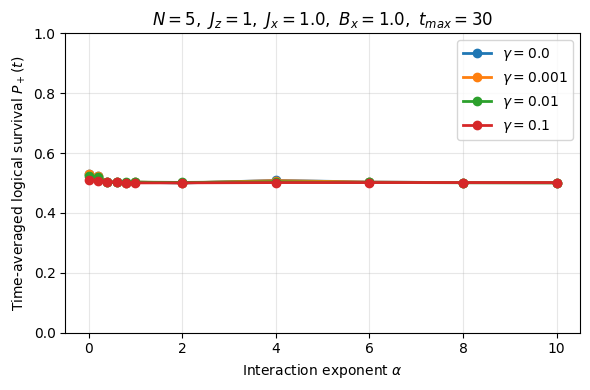

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# Parameters
# =========================

N = 5
Jz = 1
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1]
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax_cut = 30

data_dir = "ED_Data/OpenMemory/LogicalBitFlip"

plt.figure(figsize=(6,4))

# =========================
# Loop over gamma
# =========================

for gamma in gammas:

    P_avg_list = []

    for alpha in alphas:

        filename = (
            f"{data_dir}/"
            f"LogicalSurvival_N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        times = df["time"].to_numpy()
        P_t = df["P_logical"].to_numpy()

        # =========================
        # time average over window
        # =========================

        mask = times <= tmax_cut

        P_avg = np.trapezoid(P_t[mask], times[mask]) / tmax_cut

        P_avg_list.append(P_avg)

    plt.plot(alphas, P_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(r"Time-averaged logical survival $P_+(t)$")
plt.ylim(0, 1)

plt.title(
    rf"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx},\ t_{{max}}={tmax_cut}$"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

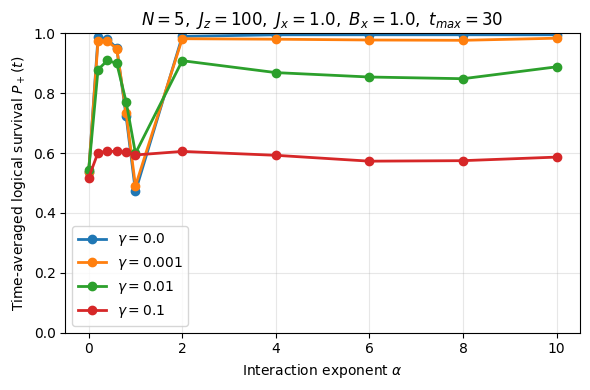

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# Parameters
# =========================

N = 5
Jz = 100
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1]
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax_cut = 30

data_dir = "ED_Data/OpenMemory/LogicalBitFlip"

plt.figure(figsize=(6,4))

# =========================
# Loop over gamma
# =========================

for gamma in gammas:

    P_avg_list = []

    for alpha in alphas:

        filename = (
            f"{data_dir}/"
            f"LogicalSurvival_N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        times = df["time"].to_numpy()
        P_t = df["P_logical"].to_numpy()

        # =========================
        # time average over window
        # =========================

        mask = times <= tmax_cut

        P_avg = np.trapezoid(P_t[mask], times[mask]) / tmax_cut

        P_avg_list.append(P_avg)

    plt.plot(alphas, P_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(r"Time-averaged logical survival $P_+(t)$")
plt.ylim(0, 1)

plt.title(
    rf"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx},\ t_{{max}}={tmax_cut}$"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

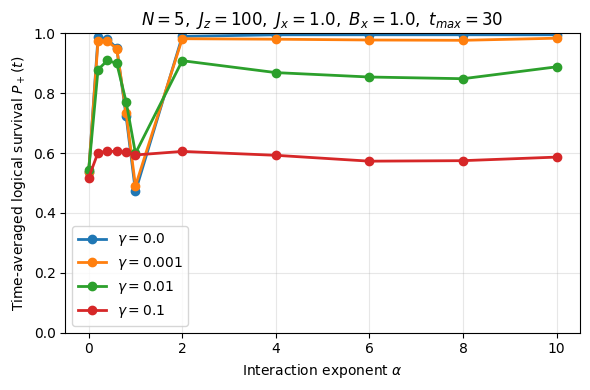

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# Parameters
# =========================

N = 5
Jz = 100
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1]
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax_cut = 30

data_dir = "ED_Data/OpenMemory/LogicalBitFlip"

plt.figure(figsize=(6,4))

# =========================
# Loop over gamma
# =========================

for gamma in gammas:

    P_avg_list = []

    for alpha in alphas:

        filename = (
            f"{data_dir}/"
            f"LogicalSurvival_N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        times = df["time"].to_numpy()
        P_t = df["P_logical"].to_numpy()

        # =========================
        # time average over window
        # =========================

        mask = times <= tmax_cut

        P_avg = np.trapezoid(P_t[mask], times[mask]) / tmax_cut

        P_avg_list.append(P_avg)

    plt.plot(alphas, P_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(r"Time-averaged logical survival $P_+(t)$")
plt.ylim(0, 1)

plt.title(
    rf"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx},\ t_{{max}}={tmax_cut}$"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()